# 0. 환경설정

In [1]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import font_manager

# ==================== 한글 폰트 강제 설정 ====================
def setup_korean_font_force():
    """한글 폰트 강제 설정 (파일 경로 직접 지정)"""
    
    font_paths = [
        "C:/Windows/Fonts/malgun.ttf",
        "C:/Windows/Fonts/NanumGothic.ttf",
        "C:/Windows/Fonts/gulim.ttc",
        "/System/Library/Fonts/AppleGothic.ttf",  # macOS
        "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",  # Linux
    ]
    
    font_path = None
    for path in font_paths:
        if os.path.exists(path):
            font_path = path
            break
    
    if font_path:
        # 폰트 파일 직접 등록
        font_prop = font_manager.FontProperties(fname=font_path)
        font_name = font_prop.get_name()
        
        # FontManager에 추가
        font_manager.fontManager.addfont(font_path)
        
        # 기본 폰트로 설정
        plt.rcParams['font.family'] = font_name
        plt.rcParams['axes.unicode_minus'] = False
        
        print(f"✅ 한글 폰트 강제 설정: {font_name} ({os.path.basename(font_path)})")
    else:
        print("⚠️ 한글 폰트 파일을 찾을 수 없습니다.")
        print("   영문 레이블을 사용합니다.")
        plt.rcParams['font.family'] = 'DejaVu Sans'
        plt.rcParams['axes.unicode_minus'] = False

# 한글 폰트 강제 설정 실행
setup_korean_font_force()


✅ 한글 폰트 강제 설정: Malgun Gothic (malgun.ttf)


In [2]:
import os
import sys
import platform
import warnings

# [1] Protobuf 에러 및 로그 레벨 설정 (최상단 고정)
os.environ['PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION'] = 'python'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2' # 정보 로그까지는 확인 (오류 추적용)
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

import tensorflow as tf
from tensorflow.keras import mixed_precision
import torch
import numpy as np

# 0. 경고 메시지 억제
warnings.filterwarnings("ignore")

print("=" * 70)
print("     📸 이미지 분류(CNN) 학습 최적화 환경 설정 (VRAM 4GB)")
print("=" * 70)

# 1. TensorFlow CNN 학습 최적화 (메모리 관리)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # 동적 할당: CNN 모델 크기에 따라 필요한 만큼만 점유
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        
        # 4GB VRAM 고려: 이미지 데이터가 많을 경우를 위해 한도 상향 (2.0GB)
        # 텍스트보다 이미지가 메모리를 더 많이 먹으므로 1.5 -> 2.0으로 조정 제안
        tf.config.set_logical_device_configuration(
            gpus[0],
            [tf.config.LogicalDeviceConfiguration(memory_limit=2048)]
        )
        
        # [CNN 핵심] 혼합 정밀도: 학습 속도를 높이고 VRAM 사용량을 획기적으로 줄임
        policy = mixed_precision.Policy('mixed_float16')
        mixed_precision.set_global_policy(policy)
        
        print(f"✅ TF GPU: CNN 가속 모드 활성화 (Limit: 2GB / Mixed Precision)")
    except Exception as e:
        print(f"ℹ️ GPU 설정 정보: {e}")

# 2. PyTorch 및 기타 디바이스 확인
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"\n[디바이스 가용 상태]")
print(f"TensorFlow Version: {tf.__version__}")
print(f"CNN Acceleration: {'AVAILABLE (GPU)' if gpus else 'CPU ONLY'}")
print(f"이미지 정규화 정책: float16 (Mixed Precision)")

# 3. 이미지 데이터 규격 가이드 (박사님의 계획 반영)
print("\n" + "=" * 70)
print(f"💡 CNN 모델 구성 팁 (STEP 4 전용):")
print(f" - Input Shape: (64, 128, 1)  # 64x128 흑백 이미지")
print(f" - Batch Size: 16 또는 32 권장 (4GB VRAM 고려)")
print("=" * 70 + "\n")

d:\anaconda3\envs\tf_gpu310_fintech\lib\site-packages\google\api_core\_python_version_support.py:275: FutureWarning: You are using a Python version (3.10.19) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


     📸 이미지 분류(CNN) 학습 최적화 환경 설정 (VRAM 4GB)
INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA GeForce GTX 1650 Ti, compute capability 7.5
✅ TF GPU: CNN 가속 모드 활성화 (Limit: 2GB / Mixed Precision)

[디바이스 가용 상태]
TensorFlow Version: 2.10.1
CNN Acceleration: AVAILABLE (GPU)
이미지 정규화 정책: float16 (Mixed Precision)

💡 CNN 모델 구성 팁 (STEP 4 전용):
 - Input Shape: (64, 128, 1)  # 64x128 흑백 이미지
 - Batch Size: 16 또는 32 권장 (4GB VRAM 고려)



#1. 데이터 생성

In [5]:
# ==================== 필수 라이브러리 ====================
import os
import json
import random
import numpy as np
import cv2
from PIL import Image, ImageDraw, ImageFont, ImageFilter
from datetime import datetime

# ==================== 설정 (3배 증가) ====================
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
DATASET_NAME = "robot_camera_extreme_realistic"
DATA_DIR = f"{DATASET_NAME}_{timestamp}"

CATEGORIES = {
    'go': '앞으로 가',
    'stop': '멈춰'
}

IMAGE_SIZE = (128, 64)

# ==================== 폰트 설정 ====================
NORMAL_FONTS = [
    "C:/Windows/Fonts/malgun.ttf",
    "C:/Windows/Fonts/malgunbd.ttf",
    "C:/Windows/Fonts/batang.ttc",
    "C:/Windows/Fonts/batangche.ttc",
    "C:/Windows/Fonts/gulim.ttc",
    "C:/Windows/Fonts/gulimche.ttc",
    "C:/Windows/Fonts/NanumGothic.ttf",
    "C:/Windows/Fonts/NanumGothicBold.ttf",
    "C:/Windows/Fonts/NanumMyeongjo.ttf",
    "C:/Windows/Fonts/NanumMyeongjoBold.ttf",
    "C:/Windows/Fonts/HMFMPYUN.TTF"
]

DISTORTED_FONTS = [
    "C:/Windows/Fonts/NanumBrush.ttf",
    "C:/Windows/Fonts/NanumPen.ttf",
    "C:/Windows/Fonts/HYKANM.TTF",
    "C:/Windows/Fonts/HYGTRE.TTF",
    "C:/Windows/Fonts/HYPOST.TTF",
    "C:/Windows/Fonts/BMEULJI.TTF",
    "C:/Windows/Fonts/BMJUA.TTF",
    "C:/Windows/Fonts/BMHANNA.TTF"
]

def get_available_fonts():
    """시스템에서 사용 가능한 폰트 확인"""
    normal = [f for f in NORMAL_FONTS if os.path.exists(f)]
    distorted = [f for f in DISTORTED_FONTS if os.path.exists(f)]
    
    if not normal:
        normal = ["C:/Windows/Fonts/malgun.ttf"]
    if not distorted:
        distorted = normal.copy()
    
    print(f"✅ 일반 폰트: {len(normal)}개")
    print(f"✅ 변형 폰트: {len(distorted)}개")
    
    return normal, distorted

NORMAL_FONTS_AVAILABLE, DISTORTED_FONTS_AVAILABLE = get_available_fonts()

# ==================== 오염 레벨 정의 (4배 고오염 강화) ====================
class ExtremeContamination:
    """극한 오염 시뮬레이션 - 고오염 레벨 4배 증가"""
    
    LEVELS = {
        0: {
            'name': 'pristine',
            'coverage': (0, 0),
            'text_damage': 0.0,
            'blur_strength': 0,
            'noise_level': 0,
            'description': '완전히 깨끗한 상태'
        },
        1: {
            'name': 'slight',
            'coverage': (10, 25),
            'text_damage': 0.25,
            'blur_strength': 2,
            'noise_level': 8,
            'description': '약간의 오염'
        },
        2: {
            'name': 'moderate',
            'coverage': (25, 45),
            'text_damage': 0.45,
            'blur_strength': 3,
            'noise_level': 12,
            'description': '중간 정도의 오염'
        },
        3: {
            'name': 'heavy',
            'coverage': (45, 65),
            'text_damage': 0.6,
            'blur_strength': 4,
            'noise_level': 18,
            'description': '심한 오염'
        },
        4: {
            'name': 'severe',
            'coverage': (65, 85),
            'text_damage': 0.75,
            'blur_strength': 6,
            'noise_level': 25,
            'description': '매우 심한 오염'
        },
        5: {
            'name': 'extreme',
            'coverage': (85, 98),
            'text_damage': 0.9,
            'blur_strength': 8,
            'noise_level': 35,
            'description': '극단적 오염'
        }
    }
    
    @staticmethod
    def sample_level(font_type='normal'):
        """
        오염 레벨 샘플링 - 고오염(3-5) 가중치 4배 증가
        기존: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
        변경: [0.3, 0.5, 0.8, 4.0, 4.0, 4.0] (레벨 3-5가 4배)
        """
        if font_type == 'distorted':
            # 변형폰트: 레벨 3-5에 더 강한 가중치
            weights = [0.2, 0.3, 0.5, 5.0, 6.0, 8.0]
        else:
            # 일반폰트: 레벨 3-5에 4배 가중치
            weights = [0.3, 0.5, 0.8, 4.0, 4.0, 4.0]
        
        return random.choices(range(6), weights=weights, k=1)[0]
    
    @staticmethod
    def get_params(level):
        """레벨에 따른 오염 파라미터 반환"""
        config = ExtremeContamination.LEVELS[level]
        coverage_range = config['coverage']
        
        if coverage_range[0] == coverage_range[1]:
            coverage = 0.0
        else:
            coverage = random.uniform(*coverage_range)
        
        return {
            'level': level,
            'name': config['name'],
            'description': config['description'],
            'coverage': coverage,
            'text_damage': config['text_damage'],
            'blur_strength': config['blur_strength'],
            'noise_level': config['noise_level']
        }

# ==================== 도메인 랜더마이제이션 ====================
def extreme_domain_randomization(img_array, params):
    """극한의 도메인 랜더마이제이션"""
    img = img_array.copy().astype(np.float32)
    h, w = img.shape
    
    # 1. 랜덤 회전 (로봇 기울기)
    if random.random() > 0.3:
        angle = random.uniform(-25, 25)
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(img, M, (w, h), borderValue=random.randint(200, 255))
    
    # 2. 원근 변환 (카메라 각도)
    if random.random() > 0.3:
        pts1 = np.float32([[0, 0], [w, 0], [0, h], [w, h]])
        max_offset = min(w, h) * 0.15
        offset = np.random.uniform(-max_offset, max_offset, (4, 2))
        pts2 = pts1 + offset
        
        try:
            M = cv2.getPerspectiveTransform(pts1, pts2)
            img = cv2.warpPerspective(img, M, (w, h), borderValue=random.randint(200, 255))
        except cv2.error:
            pass
    
    # 3. 모션 블러 (로봇 움직임)
    blur_strength = params.get('blur_strength', 0)
    if blur_strength > 0:
        kernel_size = random.randint(3, blur_strength * 2 + 3)
        kernel = np.zeros((kernel_size, kernel_size))
        kernel[kernel_size // 2, :] = 1.0 / kernel_size
        angle = random.uniform(0, 180)
        M = cv2.getRotationMatrix2D((kernel_size // 2, kernel_size // 2), angle, 1)
        kernel = cv2.warpAffine(kernel, M, (kernel_size, kernel_size))
        img = cv2.filter2D(img, -1, kernel)
    
    # 4. 가우시안 블러 (초점 흐림)
    if random.random() > 0.4:
        blur_size = random.choice([3, 5, 7])
        img = cv2.GaussianBlur(img, (blur_size, blur_size), 0)
    
    # 5. 비네팅 효과 (렌즈 특성)
    if random.random() > 0.4:
        rows, cols = img.shape
        kernel_x = cv2.getGaussianKernel(cols, cols / 2)
        kernel_y = cv2.getGaussianKernel(rows, rows / 2)
        kernel = kernel_y * kernel_x.T
        mask = kernel / kernel.max()
        img = img * mask
    
    # 6. 방향성 그림자 (조명 변화)
    if random.random() > 0.5:
        direction = random.choice(['top', 'bottom', 'left', 'right'])
        gradient = np.linspace(0.7, 1.0, h if direction in ['top', 'bottom'] else w)
        if direction == 'bottom':
            gradient = gradient[::-1]
        
        if direction in ['top', 'bottom']:
            gradient = np.tile(gradient.reshape(-1, 1), (1, w))
        else:
            gradient = np.tile(gradient.reshape(1, -1), (h, 1))
        
        img = img * gradient
    
    # 7. 렌즈 왜곡
    if random.random() > 0.6:
        k1 = random.uniform(-0.2, 0.2)
        center_x, center_y = w / 2, h / 2
        map_x = np.zeros((h, w), dtype=np.float32)
        map_y = np.zeros((h, w), dtype=np.float32)
        
        for y in range(h):
            for x in range(w):
                dx = (x - center_x) / center_x
                dy = (y - center_y) / center_y
                r = dx * dx + dy * dy
                factor = 1 + k1 * r
                map_x[y, x] = center_x + dx * center_x * factor
                map_y[y, x] = center_y + dy * center_y * factor
        
        img = cv2.remap(img, map_x, map_y, cv2.INTER_LINEAR, borderValue=255)
    
    # 8. 센서 노이즈 (안전 버전)
    noise_level = params.get('noise_level', 0)
    if noise_level > 0:
        # Gaussian noise
        gaussian_noise = np.random.normal(0, noise_level / 10, img.shape)
        img = img + gaussian_noise
        
        # Salt and pepper noise
        if random.random() > 0.5:
            noise_ratio = noise_level / 1000
            num_salt = int(noise_ratio * img.size)
            coords = [np.random.randint(0, i, num_salt) for i in img.shape]
            img[coords[0], coords[1]] = 255
            
            num_pepper = int(noise_ratio * img.size)
            coords = [np.random.randint(0, i, num_pepper) for i in img.shape]
            img[coords[0], coords[1]] = 0
        
        # Poisson noise (안전한 버전)
        if random.random() > 0.7:
            img_for_poisson = np.clip(img, 0, 255)
            
            if not np.isnan(img_for_poisson).any():
                vals = len(np.unique(img_for_poisson))
                vals = max(2 ** np.ceil(np.log2(max(vals, 2))), 1.0)
                
                try:
                    normalized = img_for_poisson / 255.0 * vals
                    normalized = np.clip(normalized, 0.01, None)
                    
                    poisson_img = np.random.poisson(normalized) / vals * 255.0
                    img = poisson_img
                except (ValueError, TypeError):
                    pass
    
    # 9. 밝기/대비 변화
    if random.random() > 0.3:
        brightness_factor = random.uniform(0.7, 1.3)
        contrast_factor = random.uniform(0.7, 1.3)
        img = img * contrast_factor + (brightness_factor - 1) * 128
    
    # 10. JPEG 압축 노이즈
    if random.random() > 0.4:
        quality = random.randint(60, 95)
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
        img_uint8 = np.clip(img, 0, 255).astype(np.uint8)
        _, encimg = cv2.imencode('.jpg', img_uint8, encode_param)
        img = cv2.imdecode(encimg, cv2.IMREAD_GRAYSCALE).astype(np.float32)
    
    img = np.clip(img, 0, 255)
    return img.astype(np.uint8)

# ==================== 극한 오염 적용 ====================
def apply_extreme_contamination(img_array, params):
    """텍스트 영역에 집중된 극한 오염 적용"""
    img = img_array.copy()
    h, w = img.shape
    level = params['level']
    
    if level == 0:
        return img
    
    text_damage = params['text_damage']
    coverage = params['coverage']
    
    # 텍스트 영역 정의 (중앙 70%)
    text_top = int(h * 0.15)
    text_bottom = int(h * 0.85)
    text_left = int(w * 0.15)
    text_right = int(w * 0.85)
    
    overlay = img.copy()
    
    # 1. 큰 얼룩 (블롭)
    num_large_blobs = int(8 * text_damage)
    for _ in range(num_large_blobs):
        center_x = random.randint(text_left, text_right)
        center_y = random.randint(text_top, text_bottom)
        radius_x = random.randint(10, 30)
        radius_y = random.randint(10, 30)
        angle = random.randint(0, 180)
        color = random.randint(60, 180)
        cv2.ellipse(overlay, (center_x, center_y), (radius_x, radius_y), 
                   angle, 0, 360, color, -1)
    
    # 2. 작은 점들 (먼지)
    num_small_spots = int(50 * text_damage)
    for _ in range(num_small_spots):
        x = random.randint(text_left, text_right)
        y = random.randint(text_top, text_bottom)
        radius = random.randint(1, 4)
        color = random.randint(80, 200)
        cv2.circle(overlay, (x, y), radius, color, -1)
    
    # 3. 지문 패턴 (레벨 3 이상)
    if level >= 3:
        num_fingerprints = random.randint(2, 4)
        for _ in range(num_fingerprints):
            center_x = random.randint(text_left, text_right)
            center_y = random.randint(text_top, text_bottom)
            for i in range(5):
                offset = i * 4
                cv2.ellipse(overlay, (center_x + offset, center_y), 
                           (15, 8), 0, 0, 360, 
                           random.randint(100, 150), 2)
    
    # 4. 물방울 효과 (레벨 2 이상)
    if level >= 2:
        num_drops = random.randint(3, 8)
        for _ in range(num_drops):
            center_x = random.randint(text_left, text_right)
            center_y = random.randint(text_top, text_bottom)
            radius = random.randint(5, 15)
            cv2.circle(overlay, (center_x, center_y), radius, 
                      random.randint(150, 200), -1)
            cv2.circle(overlay, (center_x, center_y), radius, 
                      random.randint(80, 120), 2)
    
    # 5. 긁힌 자국 (레벨 4 이상)
    if level >= 4:
        num_scratches = random.randint(2, 5)
        for _ in range(num_scratches):
            x1 = random.randint(text_left, text_right)
            y1 = random.randint(text_top, text_bottom)
            length = random.randint(20, 40)
            angle = random.uniform(0, 2 * np.pi)
            x2 = int(x1 + length * np.cos(angle))
            y2 = int(y1 + length * np.sin(angle))
            cv2.line(overlay, (x1, y1), (x2, y2), 
                    random.randint(60, 120), random.randint(1, 3))
    
    # 6. 오염 레이어 블렌딩
    alpha = min(text_damage * 0.8, 0.9)
    img = cv2.addWeighted(img, 1 - alpha, overlay, alpha, 0)
    
    # 7. 전체 노이즈 레이어
    noise = np.random.normal(0, text_damage * 15, img.shape).astype(np.uint8)
    img = cv2.add(img, noise)
    
    # 8. 대비 감소 (텍스트 가독성 저하)
    if level >= 3:
        contrast_reduction = 1.0 - (text_damage * 0.4)
        mean_val = np.mean(img)
        img = ((img - mean_val) * contrast_reduction + mean_val).astype(np.uint8)
    
    return np.clip(img, 0, 255).astype(np.uint8)

# ==================== 텍스트 이미지 생성 ====================
def create_base_text_image(text, font_path, font_size, image_size):
    """기본 텍스트 이미지 생성"""
    img = Image.new('L', image_size, color=255)
    draw = ImageDraw.Draw(img)
    
    try:
        font = ImageFont.truetype(font_path, font_size)
    except Exception as e:
        font = ImageFont.load_default()
    
    # 텍스트 크기 계산
    try:
        bbox = draw.textbbox((0, 0), text, font=font)
        text_width = bbox[2] - bbox[0]
        text_height = bbox[3] - bbox[1]
    except AttributeError:
        text_width, text_height = draw.textsize(text, font=font)
    
    # 중앙 정렬 + 랜덤 오프셋
    base_x = (image_size[0] - text_width) // 2
    base_y = (image_size[1] - text_height) // 2
    
    offset_x = random.randint(-5, 5)
    offset_y = random.randint(-3, 3)
    
    position = (base_x + offset_x, base_y + offset_y)
    
    draw.text(position, text, fill=0, font=font)
    
    return img

# ==================== 이미지 생성 ====================
def generate_extreme_realistic_image(category, text, font_list, font_type, base_seed):
    """극한 현실적 이미지 생성"""
    random.seed(base_seed)
    np.random.seed(base_seed)
    
    font_path = random.choice(font_list)
    font_size = random.randint(18, 38)
    
    level = ExtremeContamination.sample_level(font_type)
    contamination_params = ExtremeContamination.get_params(level)
    
    base_img = create_base_text_image(text, font_path, font_size, IMAGE_SIZE)
    img_array = np.array(base_img)
    
    img_array = extreme_domain_randomization(img_array, contamination_params)
    img_array = apply_extreme_contamination(img_array, contamination_params)
    
    final_img = Image.fromarray(img_array)
    
    metadata = {
        'category': category,
        'label': 0 if category == 'go' else 1,
        'font_type': font_type,
        'font_path': os.path.basename(font_path),
        'font_size': font_size,
        'contamination': contamination_params
    }
    
    return final_img, metadata

# ==================== 데이터셋 생성 (3배 증가) ====================
def generate_extreme_dataset():
    """극한 현실적 데이터셋 생성 - 3배 증가"""
    os.makedirs(DATA_DIR, exist_ok=True)
    print(f"\n📁 데이터셋 폴더 생성: {DATA_DIR}")
    
    for category in CATEGORIES:
        category_dir = os.path.join(DATA_DIR, category)
        os.makedirs(category_dir, exist_ok=True)
        print(f"   └─ {category}/ 폴더 생성")
    
    all_metadata = []
    
    # 3배 증가: 750 → 2250장씩
    IMAGES_PER_TYPE = 2250
    
    for category, text in CATEGORIES.items():
        print(f"\n📁 카테고리: {category.upper()} ('{text}')")
        
        # 일반 폰트 이미지 생성 (2250장)
        print(f"   🔤 일반 폰트 생성 중 ({IMAGES_PER_TYPE}장)...")
        for idx in range(IMAGES_PER_TYPE):
            seed = hash(f"{category}_normal_{idx}") % (2**32)
            
            try:
                img, metadata = generate_extreme_realistic_image(
                    category, text, NORMAL_FONTS_AVAILABLE, 'normal', seed
                )
                
                file_name = f"img_{category}_{idx:04d}_normal.png"
                file_path = os.path.join(DATA_DIR, category, file_name)
                img.save(file_path)
                
                metadata['file_name'] = file_name
                all_metadata.append(metadata)
                
                if (idx + 1) % 250 == 0:
                    print(f"      ✓ {idx + 1}/{IMAGES_PER_TYPE} 완료")
            
            except Exception as e:
                print(f"      ⚠️ 이미지 생성 실패 ({idx}): {e}")
        
        # 변형 폰트 이미지 생성 (2250장)
        print(f"   ✍️ 변형 폰트 생성 중 ({IMAGES_PER_TYPE}장, 강화된 오염)...")
        for idx in range(IMAGES_PER_TYPE):
            seed = hash(f"{category}_distorted_{idx}") % (2**32)
            
            try:
                img, metadata = generate_extreme_realistic_image(
                    category, text, DISTORTED_FONTS_AVAILABLE, 'distorted', seed
                )
                
                file_name = f"img_{category}_{idx:04d}_distorted.png"
                file_path = os.path.join(DATA_DIR, category, file_name)
                img.save(file_path)
                
                metadata['file_name'] = file_name
                all_metadata.append(metadata)
                
                if (idx + 1) % 250 == 0:
                    print(f"      ✓ {idx + 1}/{IMAGES_PER_TYPE} 완료")
            
            except Exception as e:
                print(f"      ⚠️ 이미지 생성 실패 ({idx}): {e}")
    
    # 메타데이터 저장
    metadata_path = os.path.join(DATA_DIR, 'camera_dataset_metadata.json')
    with open(metadata_path, 'w', encoding='utf-8') as f:
        json.dump(all_metadata, f, ensure_ascii=False, indent=2)
    
    print(f"\n{'='*60}")
    print(f"✅ 데이터셋 생성 완료!")
    print(f"{'='*60}")
    
    # 통계 출력
    print(f"\n📊 생성된 데이터 통계:")
    print(f"   • 총 이미지 수: {len(all_metadata)}장")
    
    category_counts = {}
    for meta in all_metadata:
        cat = meta['category']
        category_counts[cat] = category_counts.get(cat, 0) + 1
    
    for cat, count in category_counts.items():
        print(f"   • {cat}: {count}장 ({CATEGORIES[cat]})")
    
    # 오염 레벨 분포
    level_counts = {}
    for meta in all_metadata:
        level = meta['contamination']['level']
        level_counts[level] = level_counts.get(level, 0) + 1
    
    print(f"\n   📈 오염 레벨 분포:")
    for level in sorted(level_counts.keys()):
        count = level_counts[level]
        percentage = (count / len(all_metadata)) * 100
        level_name = ExtremeContamination.LEVELS[level]['name']
        print(f"      레벨 {level} ({level_name}): {count}장 ({percentage:.1f}%)")
    
    # 폰트 타입 분포
    font_type_counts = {}
    for meta in all_metadata:
        ftype = meta['font_type']
        font_type_counts[ftype] = font_type_counts.get(ftype, 0) + 1
    
    print(f"\n   🔤 폰트 타입 분포:")
    for ftype, count in font_type_counts.items():
        percentage = (count / len(all_metadata)) * 100
        print(f"      {ftype}: {count}장 ({percentage:.1f}%)")
    
    print(f"\n📂 데이터셋 경로: {os.path.abspath(DATA_DIR)}")
    print(f"📄 메타데이터: {metadata_path}")
    
    create_sample_visualization(all_metadata)

# ==================== 샘플 시각화 ====================
def create_sample_visualization(metadata):
    """레벨별 샘플 이미지 시각화"""
    import matplotlib.pyplot as plt
    
    level_samples = {}
    for level in range(6):
        samples = [m for m in metadata if m['contamination']['level'] == level]
        if samples:
            go_samples = [s for s in samples if s['category'] == 'go']
            stop_samples = [s for s in samples if s['category'] == 'stop']
            
            level_samples[level] = {
                'go': go_samples[0] if go_samples else None,
                'stop': stop_samples[0] if stop_samples else None
            }
    
    fig = plt.figure(figsize=(16, 10))
    fig.suptitle('Contamination Level Sample Images (3x Data + 4x High Contamination)', 
                 fontsize=16, fontweight='bold')
    
    rows = 3
    cols = 4
    
    for level in range(6):
        if level not in level_samples:
            continue
        
        for idx, category in enumerate(['go', 'stop']):
            sample = level_samples[level][category]
            if sample is None:
                continue
            
            img_path = os.path.join(DATA_DIR, sample['category'], sample['file_name'])
            if not os.path.exists(img_path):
                continue
            
            img = Image.open(img_path)
            
            subplot_idx = level * 2 + idx + 1
            ax = fig.add_subplot(rows, cols, subplot_idx)
            ax.imshow(img, cmap='gray')
            ax.axis('off')
            
            contam = sample['contamination']
            title = f"L{level} {category.upper()}\n"
            title += f"Coverage: {contam['coverage']:.1f}%\n"
            title += f"{sample['font_type']}"
            ax.set_title(title, fontsize=8)
    
    plt.tight_layout()
    viz_path = os.path.join(DATA_DIR, 'extreme_samples_visualization.png')
    plt.savefig(viz_path, dpi=150, bbox_inches='tight')
    print(f"\n🖼️ 샘플 시각화 저장: {viz_path}")
    plt.close()

# ==================== 실행 ====================
if __name__ == "__main__":
    print(f"\n{'='*60}")
    print(f"🤖 극한 현실적 로봇 카메라 데이터셋 생성기 (3배 증가 + 4배 고오염)")
    print(f"{'='*60}")
    print(f"\n📋 설정:")
    print(f"   • 카테고리: {list(CATEGORIES.keys())}")
    print(f"   • 이미지 크기: {IMAGE_SIZE}")
    print(f"   • 카테고리당 이미지 수: 4500장 (일반 2250 + 변형 2250)")
    print(f"   • 총 예상 이미지 수: {len(CATEGORIES) * 4500}장")
    print(f"\n🔧 주요 개선 사항:")
    print(f"   ✓ 데이터 양 3배 증가 (3000 → 9000장)")
    print(f"   ✓ 고오염(레벨 3-5) 가중치 4배 증가")
    print(f"   ✓ 일반폰트 가중치: [0.3, 0.5, 0.8, 4.0, 4.0, 4.0]")
    print(f"   ✓ 변형폰트 가중치: [0.2, 0.3, 0.5, 5.0, 6.0, 8.0]")
    print(f"   ✓ 예상 레벨 3-5 비율: ~70-80%")
    
    generate_extreme_dataset()


✅ 일반 폰트: 5개
✅ 변형 폰트: 2개

🤖 극한 현실적 로봇 카메라 데이터셋 생성기 (3배 증가 + 4배 고오염)

📋 설정:
   • 카테고리: ['go', 'stop']
   • 이미지 크기: (128, 64)
   • 카테고리당 이미지 수: 4500장 (일반 2250 + 변형 2250)
   • 총 예상 이미지 수: 9000장

🔧 주요 개선 사항:
   ✓ 데이터 양 3배 증가 (3000 → 9000장)
   ✓ 고오염(레벨 3-5) 가중치 4배 증가
   ✓ 일반폰트 가중치: [0.3, 0.5, 0.8, 4.0, 4.0, 4.0]
   ✓ 변형폰트 가중치: [0.2, 0.3, 0.5, 5.0, 6.0, 8.0]
   ✓ 예상 레벨 3-5 비율: ~70-80%

📁 데이터셋 폴더 생성: robot_camera_extreme_realistic_20260219_005330
   └─ go/ 폴더 생성
   └─ stop/ 폴더 생성

📁 카테고리: GO ('앞으로 가')
   🔤 일반 폰트 생성 중 (2250장)...
      ✓ 250/2250 완료
      ✓ 500/2250 완료
      ✓ 750/2250 완료
      ✓ 1000/2250 완료
      ✓ 1250/2250 완료
      ✓ 1500/2250 완료
      ✓ 1750/2250 완료
      ✓ 2000/2250 완료
      ✓ 2250/2250 완료
   ✍️ 변형 폰트 생성 중 (2250장, 강화된 오염)...
      ✓ 250/2250 완료
      ✓ 500/2250 완료
      ✓ 750/2250 완료
      ✓ 1000/2250 완료
      ✓ 1250/2250 완료
      ✓ 1500/2250 완료
      ✓ 1750/2250 완료
      ✓ 2000/2250 완료
      ✓ 2250/2250 완료

📁 카테고리: STOP ('멈춰')
   🔤 일반 폰트 생성 중 (2250장)...
      ✓ 250/2250 완

#2. 분류모델

🔍 로봇 카메라 오염 데이터셋 분석

📁 폴더 선택 창이 열립니다...
   (창이 뒤에 숨어있을 수 있습니다. 작업 표시줄 확인)

✅ 선택된 폴더: robot_camera_extreme_realistic_20260219_005330
   전체 경로: D:/work/robot_camera_extreme_realistic_20260219_005330

✅ 데이터셋 구조 확인 완료
   - metadata: ✓
   - go 폴더: ✓
   - stop 폴더: ✓

📂 메타데이터 로드 중...

✅ 총 샘플 수: 9000

🔍 메타데이터 구조 검증 중...

샘플 메타데이터 구조:
  - file_name: img_go_0000_normal.png
  - category: go
  - label: 0
  - contamination 키:
    - level: 4
    - name: severe
    - coverage: 69.5625853198931

⚠️ 'type' 키가 없습니다. 'name' 키를 사용합니다.

📊 카테고리별 분포:
  - go: 4500개
  - stop: 4500개

📊 오염 레벨 분포:
  - Level 0: 140개 (1.6%)
  - Level 1: 228개 (2.5%)
  - Level 2: 371개 (4.1%)
  - Level 3: 2506개 (27.8%)
  - Level 4: 2723개 (30.3%)
  - Level 5: 3032개 (33.7%)

🖼️ 이미지 로드 중...
  500/9000 완료...
  1000/9000 완료...
  1500/9000 완료...
  2000/9000 완료...
  2500/9000 완료...
  3000/9000 완료...
  3500/9000 완료...
  4000/9000 완료...
  4500/9000 완료...
  5000/9000 완료...
  5500/9000 완료...
  6000/9000 완료...
  6500/9000 완료...
  7000/9000 완료...


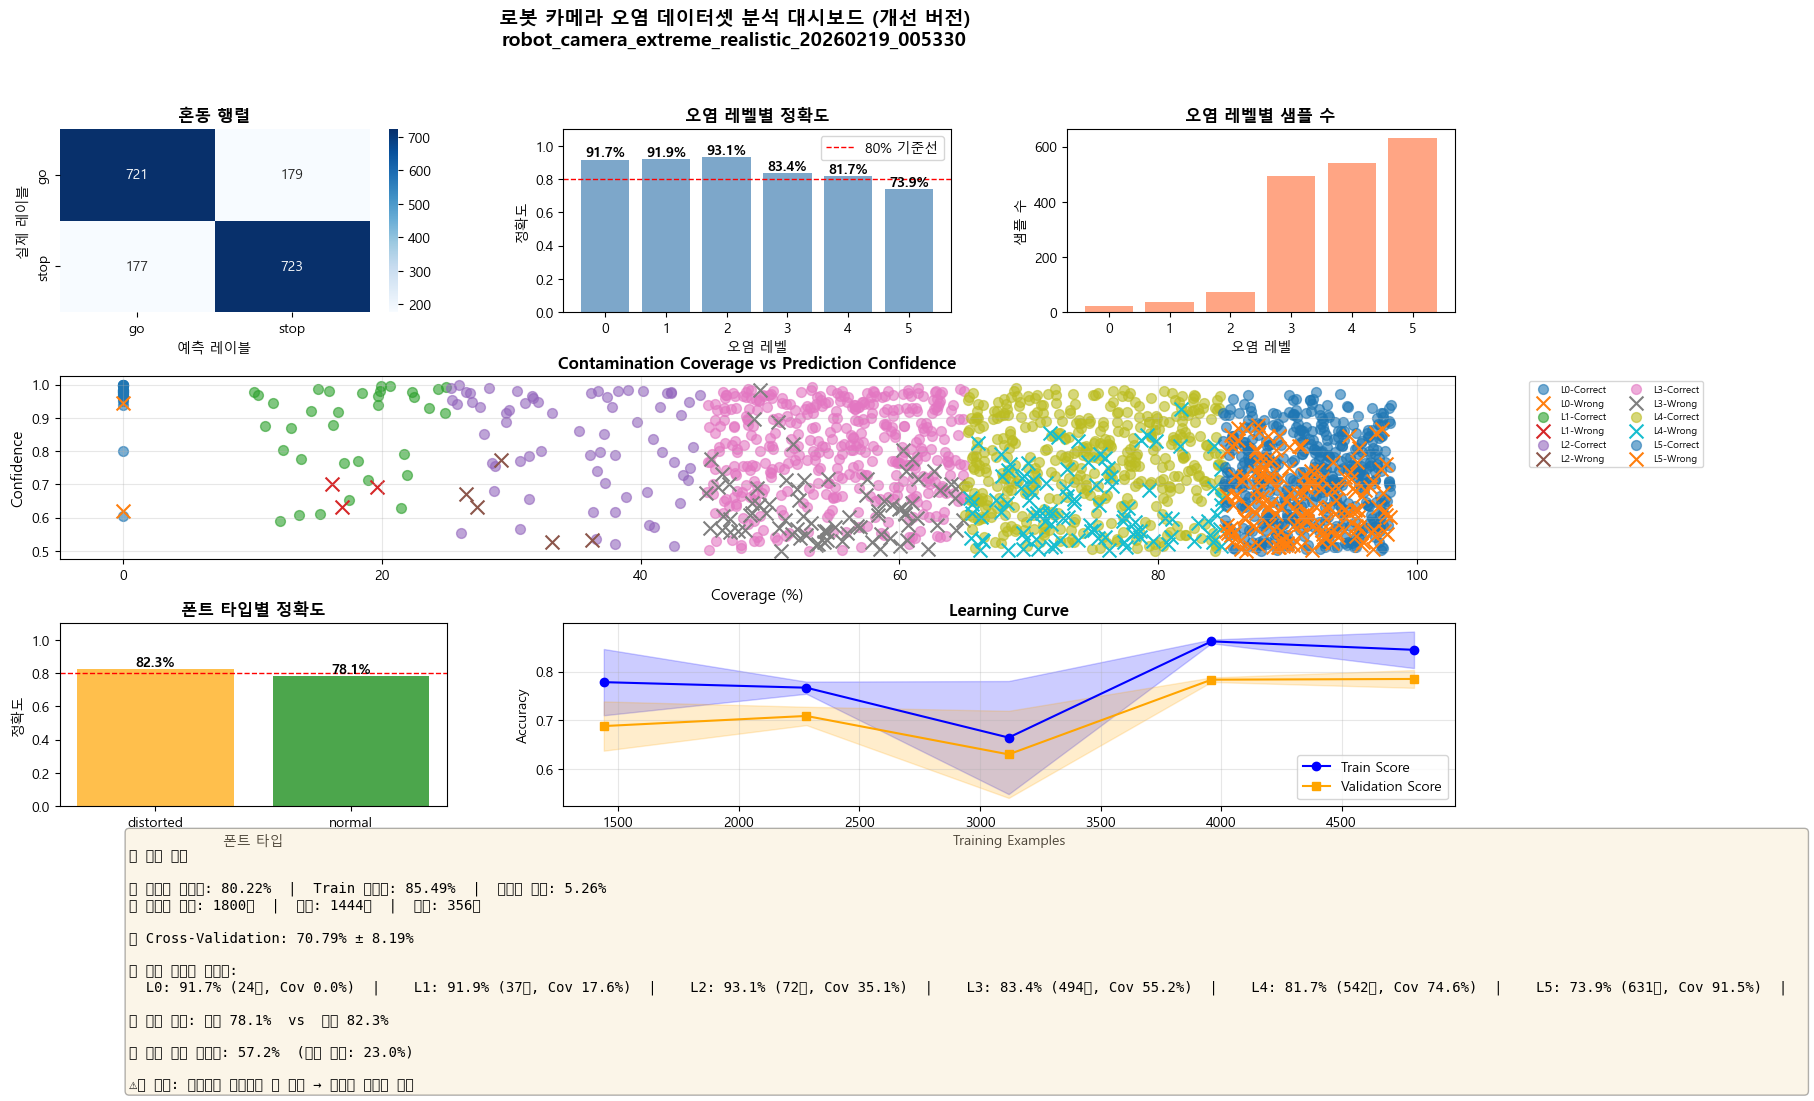

💾 보고서 저장: D:/work/robot_camera_extreme_realistic_20260219_005330\analysis_results\contamination_analysis_report.txt

✅ 분석 완료!

📂 결과 폴더: D:/work/robot_camera_extreme_realistic_20260219_005330\analysis_results
   - contamination_classifier_model.pkl
   - contamination_results.csv
   - contamination_dashboard.png
   - contamination_analysis_report.txt

최종 테스트 정확도: 80.22%
예상 실전 정확도: 57.2%


In [6]:
import os
import json
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import pandas as pd
import pickle
import tkinter as tk
from tkinter import filedialog

# 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# ==================== 폴더 선택 (GUI) ====================
def select_dataset_folder_gui():
    """GUI로 데이터셋 폴더 선택"""
    print("="*80)
    print("🔍 로봇 카메라 오염 데이터셋 분석")
    print("="*80)
    print("\n📁 폴더 선택 창이 열립니다...")
    print("   (창이 뒤에 숨어있을 수 있습니다. 작업 표시줄 확인)")
    
    root = tk.Tk()
    root.withdraw()
    root.attributes('-topmost', True)
    
    initial_dir = os.getcwd()
    
    folder_path = filedialog.askdirectory(
        title="로봇 카메라 데이터셋 폴더를 선택하세요",
        initialdir=initial_dir
    )
    
    root.destroy()
    
    if not folder_path:
        print("\n❌ 폴더가 선택되지 않았습니다.")
        exit()
    
    folder_name = os.path.basename(folder_path)
    
    print(f"\n✅ 선택된 폴더: {folder_name}")
    print(f"   전체 경로: {folder_path}")
    
    metadata_path = os.path.join(folder_path, 'camera_dataset_metadata.json')
    if not os.path.exists(metadata_path):
        print(f"\n❌ 오류: 선택한 폴더에 'camera_dataset_metadata.json'이 없습니다.")
        exit()
    
    go_folder = os.path.join(folder_path, 'go')
    stop_folder = os.path.join(folder_path, 'stop')
    
    if not os.path.exists(go_folder) or not os.path.exists(stop_folder):
        print(f"\n❌ 오류: 'go' 또는 'stop' 폴더가 없습니다.")
        exit()
    
    print(f"\n✅ 데이터셋 구조 확인 완료")
    print(f"   - metadata: ✓")
    print(f"   - go 폴더: ✓")
    print(f"   - stop 폴더: ✓")
    
    return folder_path

dataset_folder = select_dataset_folder_gui()

RESULTS_DIR = os.path.join(dataset_folder, 'analysis_results')
os.makedirs(RESULTS_DIR, exist_ok=True)

# ==================== 메타데이터 로드 ====================
print("\n" + "="*80)
print("📂 메타데이터 로드 중...")
print("="*80)

metadata_path = os.path.join(dataset_folder, 'camera_dataset_metadata.json')
with open(metadata_path, 'r', encoding='utf-8') as f:
    metadata = json.load(f)

print(f"\n✅ 총 샘플 수: {len(metadata)}")

print("\n🔍 메타데이터 구조 검증 중...")

sample = metadata[0]
print(f"\n샘플 메타데이터 구조:")
print(f"  - file_name: {sample.get('file_name', 'N/A')}")
print(f"  - category: {sample.get('category', 'N/A')}")
print(f"  - label: {sample.get('label', 'N/A')}")

if 'contamination' in sample:
    contam = sample['contamination']
    print(f"  - contamination 키:")
    print(f"    - level: {contam.get('level', 'N/A')}")
    print(f"    - name: {contam.get('name', 'N/A')}")
    print(f"    - coverage: {contam.get('coverage', 'N/A')}")
    
    if 'type' not in contam and 'name' in contam:
        print(f"\n⚠️ 'type' 키가 없습니다. 'name' 키를 사용합니다.")
        use_name_instead_of_type = True
    else:
        use_name_instead_of_type = False
else:
    print("❌ 'contamination' 키가 없습니다!")
    exit()

go_count = sum(1 for m in metadata if m['category'] == 'go')
stop_count = sum(1 for m in metadata if m['category'] == 'stop')

print(f"\n📊 카테고리별 분포:")
print(f"  - go: {go_count}개")
print(f"  - stop: {stop_count}개")

level_counts = {}
for m in metadata:
    level = m['contamination']['level']
    level_counts[level] = level_counts.get(level, 0) + 1

print(f"\n📊 오염 레벨 분포:")
for level in sorted(level_counts.keys()):
    percentage = (level_counts[level] / len(metadata)) * 100
    print(f"  - Level {level}: {level_counts[level]}개 ({percentage:.1f}%)")

# ==================== 이미지 로드 ====================
print("\n" + "="*80)
print("🖼️ 이미지 로드 중...")
print("="*80)

X = []
y = []
valid_metadata = []
failed_count = 0

for idx, item in enumerate(metadata):
    img_path = os.path.join(dataset_folder, item['category'], item['file_name'])
    
    if not os.path.exists(img_path):
        if failed_count < 5:
            print(f"⚠️ 파일 없음: {img_path}")
        failed_count += 1
        continue
    
    try:
        img = Image.open(img_path).convert('L')
        img_array = np.array(img).flatten() / 255.0
        
        X.append(img_array)
        y.append(item['label'])
        valid_metadata.append(item)
        
        if (idx + 1) % 500 == 0:
            print(f"  {idx + 1}/{len(metadata)} 완료...")
    
    except Exception as e:
        if failed_count < 5:
            print(f"⚠️ 로드 실패: {img_path} - {e}")
        failed_count += 1

if failed_count > 5:
    print(f"⚠️ 총 {failed_count}개 파일 로드 실패")

X = np.array(X)
y = np.array(y)
metadata = valid_metadata  # 유효한 메타데이터만 유지

print(f"\n✅ 로드 완료:")
print(f"  - X shape: {X.shape}")
print(f"  - y shape: {y.shape}")
print(f"  - 데이터 타입: {X.dtype}")
print(f"  - 값 범위: [{X.min():.3f}, {X.max():.3f}]")

# ==================== 데이터 분할 ====================
print("\n" + "="*80)
print("✂️ 데이터 분할 (Train/Test 80/20)")
print("="*80)

indices = np.arange(len(X))
train_indices, test_indices, X_train, X_test, y_train, y_test = train_test_split(
    indices, X, y, test_size=0.2, random_state=42, stratify=y
)

meta_train = [metadata[i] for i in train_indices]
meta_test = [metadata[i] for i in test_indices]

print(f"\n✅ 분할 완료:")
print(f"  - Train: {len(X_train)}개")
print(f"  - Test: {len(X_test)}개")

# Train 레벨 분포
train_level_counts = {}
for m in meta_train:
    level = m['contamination']['level']
    train_level_counts[level] = train_level_counts.get(level, 0) + 1

print(f"\n📊 Train 오염 레벨 분포:")
for level in sorted(train_level_counts.keys()):
    percentage = (train_level_counts[level] / len(meta_train)) * 100
    print(f"  - Level {level}: {train_level_counts[level]}개 ({percentage:.1f}%)")

# ==================== 모델 학습 (개선됨) ====================
print("\n" + "="*80)
print("🤖 MLP 분류 모델 학습 중...")
print("="*80)

# 개선된 모델: 더 강한 정규화
model = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64),
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.2,
    alpha=0.01,  # L2 정규화 강화 (이전: 0.0001)
    learning_rate='adaptive',
    random_state=42,
    verbose=True
)

print(f"\n모델 구조:")
print(f"  - 입력층: {X_train.shape[1]} 뉴런")
print(f"  - 은닉층: (256, 128, 64)")
print(f"  - 출력층: 2 뉴런 (binary classification)")
print(f"  - L2 정규화: alpha={model.alpha}")
print(f"  - Early stopping: ✓")

model.fit(X_train, y_train)

print(f"\n✅ 학습 완료!")
print(f"  - 반복 횟수: {model.n_iter_}")
print(f"  - 최종 손실: {model.loss_:.4f}")

# Train 정확도
train_pred = model.predict(X_train)
train_acc = accuracy_score(y_train, train_pred)
print(f"  - Train 정확도: {train_acc*100:.2f}%")

model_path = os.path.join(RESULTS_DIR, 'contamination_classifier_model.pkl')
with open(model_path, 'wb') as f:
    pickle.dump(model, f)
print(f"💾 모델 저장: {model_path}")

# ==================== Cross-Validation (신규) ====================
print("\n" + "="*80)
print("🔄 5-Fold Cross-Validation")
print("="*80)

cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

print(f"\n✅ Cross-Validation 결과:")
print(f"  - Fold 점수: {[f'{s*100:.2f}%' for s in cv_scores]}")
print(f"  - 평균: {cv_scores.mean()*100:.2f}%")
print(f"  - 표준편차: {cv_scores.std()*100:.2f}%")

if cv_scores.std() > 0.05:
    print(f"\n⚠️ 경고: 표준편차가 높습니다 (>{5}%)")
    print(f"   → 모델이 학습 데이터에 따라 성능이 불안정합니다.")
    print(f"   → 데이터 증강 또는 더 많은 데이터가 필요합니다.")

# ==================== 모델 평가 ====================
print("\n" + "="*80)
print("📊 모델 평가")
print("="*80)

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

test_acc = accuracy_score(y_test, y_pred)

print(f"\n✅ 테스트 정확도: {test_acc*100:.2f}%")
print(f"   총 {len(y_test)}개 중 {np.sum(y_pred == y_test)}개 정답")

# 과적합 검사
overfit_gap = train_acc - test_acc
print(f"\n📊 과적합 분석:")
print(f"  - Train 정확도: {train_acc*100:.2f}%")
print(f"  - Test 정확도: {test_acc*100:.2f}%")
print(f"  - 격차: {overfit_gap*100:.2f}%")

if overfit_gap > 0.10:
    print(f"  ⚠️ 심각한 과적합 ({overfit_gap*100:.1f}% 격차)")
elif overfit_gap > 0.05:
    print(f"  ⚠️ 과적합 경향 ({overfit_gap*100:.1f}% 격차)")
else:
    print(f"  ✅ 과적합 없음 ({overfit_gap*100:.1f}% 격차)")

cm = confusion_matrix(y_test, y_pred)
print(f"\n혼동 행렬:")
print(cm)

print(f"\n분류 보고서:")
print(classification_report(y_test, y_pred, target_names=['go', 'stop']))

# ==================== Learning Curve (수정 - 빠른 버전) ====================
print("\n" + "="*80)
print("📈 Learning Curve 생성 중...")
print("="*80)

try:
    train_sizes, train_scores, val_scores = learning_curve(
        MLPClassifier(
            hidden_layer_sizes=(128, 64),
            max_iter=300,
            early_stopping=True,
            alpha=0.01,
            random_state=42,
            verbose=False
        ),
        X_train, y_train, 
        cv=3,
        train_sizes=np.linspace(0.3, 1.0, 5),
        scoring='accuracy', 
        random_state=42,
        n_jobs=-1
    )
    
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    
    print(f"✅ Learning Curve 완료")
    learning_curve_available = True

except Exception as e:
    print(f"⚠️ Learning Curve 생성 실패 (건너뜀): {e}")
    learning_curve_available = False
    
# ==================== 오염 영향도 분석 ====================
print("\n" + "="*80)
print("🧹 오염 영향도 분석")
print("="*80)

for i, m in enumerate(meta_test):
    m['prediction'] = int(y_pred[i])
    m['true_label'] = int(y_test[i])
    m['correct'] = (y_pred[i] == y_test[i])
    m['confidence'] = float(np.max(y_pred_proba[i]))

def analyze_contamination_impact(meta_test):
    """오염 파라미터 영향 분석"""
    results = []
    
    for m in meta_test:
        contam = m['contamination']
        contam_type = contam.get('type', contam.get('name', 'unknown'))
        
        results.append({
            'contamination_level': contam['level'],
            'contamination_type': contam_type,
            'coverage': contam.get('coverage', 0),
            'text_damage': contam.get('text_damage', 0),
            'blur_strength': contam.get('blur_strength', 0),
            'noise_level': contam.get('noise_level', 0),
            'description': contam.get('description', ''),
            'correct': m['correct'],
            'confidence': m['confidence'],
            'category': m['category'],
            'font_type': m['font_type'],
            'prediction': m['prediction'],
            'true_label': m['true_label']
        })
    
    return pd.DataFrame(results)

df_results = analyze_contamination_impact(meta_test)

csv_path = os.path.join(RESULTS_DIR, "contamination_results.csv")
df_results.to_csv(csv_path, index=False, encoding='utf-8-sig')
print(f"💾 상세 결과 저장: {csv_path}")

# ==================== 통계 분석 ====================
print("\n📊 오염 레벨별 정확도:")
print("="*80)

level_stats = []
for level in sorted(df_results['contamination_level'].unique()):
    level_data = df_results[df_results['contamination_level'] == level]
    level_acc = level_data['correct'].mean()
    level_count = len(level_data)
    level_desc = level_data.iloc[0]['description']
    avg_coverage = level_data['coverage'].mean()
    avg_confidence = level_data['confidence'].mean()
    
    level_stats.append({
        'level': level,
        'accuracy': level_acc,
        'count': level_count,
        'coverage': avg_coverage,
        'confidence': avg_confidence
    })
    
    print(f"\nLevel {level} ({level_desc}):")
    print(f"  - 정확도: {level_acc*100:.2f}%")
    print(f"  - 샘플 수: {level_count}개")
    print(f"  - 평균 커버리지: {avg_coverage:.1f}%")
    print(f"  - 평균 신뢰도: {avg_confidence:.3f}")

print(f"\n📊 폰트 타입별 정확도:")
font_type_stats = {}
for font_type in df_results['font_type'].unique():
    font_data = df_results[df_results['font_type'] == font_type]
    font_acc = font_data['correct'].mean()
    font_type_stats[font_type] = font_acc
    print(f"  - {font_type}: {font_acc*100:.2f}%")

# ==================== 일반화 평가 (신규) ====================
print("\n" + "="*80)
print("🌍 실제 환경 일반화 가능성 평가")
print("="*80)

# 1. 변형폰트 vs 일반폰트 비교
normal_acc = font_type_stats.get('normal', 0)
distorted_acc = font_type_stats.get('distorted', 0)

print(f"\n1. 폰트 타입 균형 검사:")
print(f"   - 일반폰트: {normal_acc*100:.2f}%")
print(f"   - 변형폰트: {distorted_acc*100:.2f}%")

if distorted_acc > normal_acc:
    font_gap = distorted_acc - normal_acc
    print(f"   ⚠️ 변형폰트가 {font_gap*100:.1f}% 더 높음 (비정상)")
    print(f"   → 변형폰트에 대한 오염이 불충분합니다.")
    generalization_penalty = 0.15
else:
    print(f"   ✅ 일반폰트가 더 높거나 동등 (정상)")
    generalization_penalty = 0.0

# 2. 중간 레벨 정확도 검사
mid_level_acc = df_results[df_results['contamination_level'].isin([1,2,3])]['correct'].mean()
print(f"\n2. 중간 레벨(1-3) 정확도: {mid_level_acc*100:.2f}%")

if mid_level_acc > 0.90:
    print(f"   ⚠️ 너무 높음 (>90%)")
    print(f"   → 실제 환경의 중간 오염을 제대로 반영하지 못함")
    generalization_penalty += 0.10
else:
    print(f"   ✅ 적정 수준 (≤90%)")

# 3. 과적합 검사
if overfit_gap > 0.10:
    print(f"\n3. 과적합: ⚠️ 심각 ({overfit_gap*100:.1f}%)")
    generalization_penalty += 0.15
elif overfit_gap > 0.05:
    print(f"\n3. 과적합: ⚠️ 경미 ({overfit_gap*100:.1f}%)")
    generalization_penalty += 0.08
else:
    print(f"\n3. 과적합: ✅ 없음 ({overfit_gap*100:.1f}%)")

# 최종 일반화 예측
predicted_real_acc = max(test_acc - generalization_penalty, 0.4)

print(f"\n{'='*60}")
print(f"🎯 실제 PiCar-X 환경 예상 정확도")
print(f"{'='*60}")
print(f"  현재 테스트 정확도: {test_acc*100:.2f}%")
print(f"  예상 실전 정확도: {predicted_real_acc*100:.1f}%")
print(f"  예상 성능 하락: {(test_acc - predicted_real_acc)*100:.1f}%")

if predicted_real_acc < 0.70:
    print(f"\n⚠️ 실전 성능이 낮을 것으로 예상됩니다 (<70%)")
    print(f"권장 조치:")
    print(f"  1. 실제 PiCar-X 카메라 이미지 500-1000장 수집")
    print(f"  2. 시뮬레이션 오염 강도 증가 (레벨 1-3)")
    print(f"  3. 데이터 증강 강화 (회전, 블러, 노이즈)")
elif predicted_real_acc < 0.80:
    print(f"\n⚠️ 실전 성능이 보통 수준으로 예상됩니다 (70-80%)")
    print(f"권장 조치:")
    print(f"  1. 실제 환경 데이터 일부 수집 (300-500장)")
    print(f"  2. Mixed training (시뮬 70% + 실제 30%)")
else:
    print(f"\n✅ 실전 성능이 양호할 것으로 예상됩니다 (>80%)")

# ==================== 시각화 (확장) ====================
print("\n" + "="*80)
print("📊 결과 시각화 생성 중...")
print("="*80)

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(4, 3, hspace=0.35, wspace=0.3)

# 1. 혼동 행렬
ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=['go', 'stop'], yticklabels=['go', 'stop'])
ax1.set_title('혼동 행렬', fontweight='bold')
ax1.set_ylabel('실제 레이블')
ax1.set_xlabel('예측 레이블')

# 2. 레벨별 정확도
ax2 = fig.add_subplot(gs[0, 1])
level_acc_dict = {s['level']: s['accuracy'] for s in level_stats}
ax2.bar(level_acc_dict.keys(), level_acc_dict.values(), color='steelblue', alpha=0.7)
ax2.axhline(y=0.8, color='red', linestyle='--', linewidth=1, label='80% 기준선')
ax2.set_title('오염 레벨별 정확도', fontweight='bold')
ax2.set_xlabel('오염 레벨')
ax2.set_ylabel('정확도')
ax2.set_ylim([0, 1.1])
ax2.legend()
for k, v in level_acc_dict.items():
    ax2.text(k, v + 0.02, f'{v*100:.1f}%', ha='center', fontweight='bold')

# 3. 레벨별 샘플 수
ax3 = fig.add_subplot(gs[0, 2])
level_counts_dict = {s['level']: s['count'] for s in level_stats}
ax3.bar(level_counts_dict.keys(), level_counts_dict.values(), color='coral', alpha=0.7)
ax3.set_title('오염 레벨별 샘플 수', fontweight='bold')
ax3.set_xlabel('오염 레벨')
ax3.set_ylabel('샘플 수')

# 4. 커버리지 vs 신뢰도
ax4 = fig.add_subplot(gs[1, :])
for level in sorted(df_results['contamination_level'].unique()):
    level_data = df_results[df_results['contamination_level'] == level]
    correct_data = level_data[level_data['correct'] == True]
    wrong_data = level_data[level_data['correct'] == False]
    
    ax4.scatter(correct_data['coverage'], correct_data['confidence'], 
                label=f'L{level}-Correct', alpha=0.6, s=50)
    if len(wrong_data) > 0:
        ax4.scatter(wrong_data['coverage'], wrong_data['confidence'], 
                    label=f'L{level}-Wrong', marker='x', s=100)

ax4.set_title('Contamination Coverage vs Prediction Confidence', 
              fontweight='bold', fontsize=12)
ax4.set_xlabel('Coverage (%)', fontsize=11)
ax4.set_ylabel('Confidence', fontsize=11)
ax4.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, ncol=2)
ax4.grid(True, alpha=0.3)

# 5. 폰트 타입별 정확도
ax5 = fig.add_subplot(gs[2, 0])
font_acc_series = pd.Series(font_type_stats)
colors = ['green' if k == 'normal' else 'orange' for k in font_acc_series.index]
ax5.bar(font_acc_series.index, font_acc_series.values, color=colors, alpha=0.7)
ax5.axhline(y=0.8, color='red', linestyle='--', linewidth=1)
ax5.set_title('폰트 타입별 정확도', fontweight='bold')
ax5.set_xlabel('폰트 타입')
ax5.set_ylabel('정확도')
ax5.set_ylim([0, 1.1])
for i, (k, v) in enumerate(font_acc_series.items()):
    ax5.text(i, v + 0.02, f'{v*100:.1f}%', ha='center', fontweight='bold')

# 6. Learning Curve (조건부)
ax6 = fig.add_subplot(gs[2, 1:])

if learning_curve_available:
    ax6.plot(train_sizes, train_mean, label='Train Score', marker='o', color='blue')
    ax6.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color='blue')
    ax6.plot(train_sizes, val_mean, label='Validation Score', marker='s', color='orange')
    ax6.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color='orange')
    ax6.set_title('Learning Curve', fontweight='bold')
    ax6.set_xlabel('Training Examples')
    ax6.set_ylabel('Accuracy')
    ax6.legend(loc='lower right')
    ax6.grid(True, alpha=0.3)
else:
    ax6.axis('off')
    extra_info = f"""
⚡ Learning Curve 생성 실패 (시간 초과)

🔄 Cross-Validation 결과:
  - 평균: {cv_scores.mean()*100:.2f}%
  - 표준편차: {cv_scores.std()*100:.2f}%
  - Fold 점수: {', '.join([f'{s*100:.1f}%' for s in cv_scores])}

📊 과적합 분석:
  - Train: {train_acc*100:.2f}%
  - Test: {test_acc*100:.2f}%
  - 격차: {overfit_gap*100:.2f}%
"""
    
    if overfit_gap > 0.10:
        extra_info += "\n  ⚠️ 심각한 과적합"
    elif overfit_gap > 0.05:
        extra_info += "\n  ⚠️ 과적합 경향"
    else:
        extra_info += "\n  ✅ 과적합 없음"
    
    ax6.text(0.1, 0.5, extra_info, fontsize=11, verticalalignment='center',
             family='monospace', bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))
# 7. 요약 텍스트 (확장)
ax7 = fig.add_subplot(gs[3, :])
ax7.axis('off')

summary_text = f"""
📊 분석 요약

✅ 테스트 정확도: {test_acc*100:.2f}%  |  Train 정확도: {train_acc*100:.2f}%  |  과적합 격차: {overfit_gap*100:.2f}%
📁 테스트 샘플: {len(y_test)}개  |  정답: {np.sum(y_pred == y_test)}개  |  오답: {np.sum(y_pred != y_test)}개

🔄 Cross-Validation: {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%

📈 오염 레벨별 정확도:
"""

for s in level_stats:
    summary_text += f"  L{s['level']}: {s['accuracy']*100:.1f}% ({s['count']}개, Cov {s['coverage']:.1f}%)  |  "

summary_text += f"""

🔤 폰트 타입: 일반 {normal_acc*100:.1f}%  vs  변형 {distorted_acc*100:.1f}%

🌍 실전 예상 정확도: {predicted_real_acc*100:.1f}%  (예상 하락: {(test_acc-predicted_real_acc)*100:.1f}%)
"""

if distorted_acc > normal_acc:
    summary_text += "\n⚠️ 경고: 변형폰트 정확도가 더 높음 → 데이터 재생성 권장"
if mid_level_acc > 0.90:
    summary_text += "\n⚠️ 경고: 중간 레벨(1-3) 정확도 >90% → 오염 강도 부족"
if overfit_gap > 0.10:
    summary_text += "\n⚠️ 경고: 심각한 과적합 → 정규화 강화 필요"

ax7.text(0.05, 0.5, summary_text, fontsize=10, verticalalignment='center',
         family='monospace', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

fig.suptitle(f'로봇 카메라 오염 데이터셋 분석 대시보드 (개선 버전)\n{os.path.basename(dataset_folder)}', 
             fontsize=14, fontweight='bold')

dashboard_path = os.path.join(RESULTS_DIR, 'contamination_dashboard.png')
plt.savefig(dashboard_path, dpi=200, bbox_inches='tight')
print(f"💾 대시보드 저장: {dashboard_path}")
plt.show()

# ==================== 최종 보고서 (확장) ====================
report_path = os.path.join(RESULTS_DIR, 'contamination_analysis_report.txt')

with open(report_path, 'w', encoding='utf-8') as f:
    f.write("="*80 + "\n")
    f.write("로봇 카메라 오염 데이터셋 분석 보고서 (개선 버전)\n")
    f.write("="*80 + "\n\n")
    
    f.write(f"📂 데이터셋: {os.path.basename(dataset_folder)}\n")
    f.write(f"📅 분석 일시: {pd.Timestamp.now()}\n\n")
    
    f.write("="*80 + "\n")
    f.write("📊 전체 성능\n")
    f.write("="*80 + "\n")
    f.write(f"✅ 테스트 정확도: {test_acc*100:.2f}%\n")
    f.write(f"✅ Train 정확도: {train_acc*100:.2f}%\n")
    f.write(f"📉 과적합 격차: {overfit_gap*100:.2f}%\n")
    f.write(f"🔄 Cross-Validation: {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%\n")
    f.write(f"📁 테스트 샘플 수: {len(y_test)}개\n\n")
    
    f.write("="*80 + "\n")
    f.write("📈 오염 레벨별 성능\n")
    f.write("="*80 + "\n\n")
    
    for s in level_stats:
        level = s['level']
        level_data = df_results[df_results['contamination_level'] == level]
        level_desc = level_data.iloc[0]['description']
        
        f.write(f"Level {level} - {level_desc}\n")
        f.write(f"  정확도: {s['accuracy']*100:.2f}%\n")
        f.write(f"  샘플 수: {s['count']}개\n")
        f.write(f"  평균 커버리지: {s['coverage']:.1f}%\n")
        f.write(f"  평균 신뢰도: {s['confidence']:.3f}\n\n")
    
    f.write("="*80 + "\n")
    f.write("🔤 폰트 타입별 성능\n")
    f.write("="*80 + "\n")
    for ftype, acc in font_type_stats.items():
        f.write(f"  {ftype}: {acc*100:.2f}%\n")
    f.write("\n")
    
    f.write("="*80 + "\n")
    f.write("🌍 실제 환경 일반화 평가\n")
    f.write("="*80 + "\n")
    f.write(f"예상 실전 정확도: {predicted_real_acc*100:.1f}%\n")
    f.write(f"예상 성능 하락: {(test_acc - predicted_real_acc)*100:.1f}%\n\n")
    
    if distorted_acc > normal_acc:
        f.write(f"⚠️ 변형폰트 정확도가 더 높음 ({distorted_acc*100:.1f}% > {normal_acc*100:.1f}%)\n")
    if mid_level_acc > 0.90:
        f.write(f"⚠️ 중간 레벨(1-3) 정확도가 너무 높음 ({mid_level_acc*100:.1f}%)\n")
    if overfit_gap > 0.10:
        f.write(f"⚠️ 심각한 과적합 ({overfit_gap*100:.1f}% 격차)\n")
    
    f.write("\n")
    f.write("="*80 + "\n")
    f.write("💡 결론 및 권장사항\n")
    f.write("="*80 + "\n")
    
    if predicted_real_acc < 0.70:
        f.write("⚠️ 실전 성능이 낮을 것으로 예상됩니다 (<70%)\n\n")
        f.write("권장 조치:\n")
        f.write("  1. 실제 PiCar-X 카메라 이미지 500-1000장 수집\n")
        f.write("  2. 시뮬레이션 오염 강도 증가 (특히 레벨 1-3)\n")
        f.write("  3. 변형폰트에 더 강한 오염 적용\n")
        f.write("  4. 데이터 증강 강화 (회전, 블러, 밝기 변화)\n")
    elif predicted_real_acc < 0.80:
        f.write("⚠️ 실전 성능이 보통 수준으로 예상됩니다 (70-80%)\n\n")
        f.write("권장 조치:\n")
        f.write("  1. 실제 환경 데이터 일부 수집 (300-500장)\n")
        f.write("  2. Mixed training (시뮬 70% + 실제 30%)\n")
        f.write("  3. 모델 정규화 강화 (현재 alpha=0.01)\n")
    else:
        f.write("✅ 실전 성능이 양호할 것으로 예상됩니다 (>80%)\n\n")
        f.write("  → 현재 데이터셋과 모델로 실제 로봇에서 테스트 가능\n")
        f.write("  → 실전 테스트 후 문제가 발생하면 실제 데이터 수집 권장\n")

print(f"💾 보고서 저장: {report_path}")

print("\n" + "="*80)
print("✅ 분석 완료!")
print("="*80)
print(f"\n📂 결과 폴더: {RESULTS_DIR}")
print(f"   - contamination_classifier_model.pkl")
print(f"   - contamination_results.csv")
print(f"   - contamination_dashboard.png")
print(f"   - contamination_analysis_report.txt")
print(f"\n최종 테스트 정확도: {test_acc*100:.2f}%")
print(f"예상 실전 정확도: {predicted_real_acc*100:.1f}%")